

### Сценарий
Вы — Product Analyst в FocusFlow. У продукта есть бесплатный тариф и платная подписка. Руководитель сообщает: «Количество регистраций растёт, но команда не уверена, что пользователи получают ценность. Часть Android-пользователей жалуется на ошибки». Твоя задача — построить систему продуктовых метрик, проверить гипотезы и предложить приоритетное улучшение.




## Датасет и спецификация

Все таблицы — синтетические; период регистрации **01–20.09.2026**, наблюдение до **15.10.2026, 23:59:59**. `users.csv`: 1 строка = 1 зарегистрированный user_id; `channel`, `platform`, `segment`, `registration_time`. `events.csv`: 1 строка = 1 событие; `event_id`, `user_id`, `event_time`, `event_name`, `task_id`, `platform`. `payments.csv`: 1 строка = 1 успешный платёж; `payment_type` = first / renewal. `marketing_spend.csv`: затраты за весь указанный период привлечения по каналам.

**Особенности:** (1) каждое создание задачи имеет уникальный `task_id`; (2) завершение задачи не бывает без создания; (3) один пользователь может создавать много задач; (4) данное наблюдение не описывает всю будущую жизнь пользователя; (5) event `app_open` определяет активность для retention; (6) регистрация не равна платящему клиенту; (7) каналы нельзя трактовать как причинно сопоставимые без дополнительных предпосылок.

Вычисленные значения следует сопровождать единицами измерения: люди, события, проценты, ₽ и длительность.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path('.')  # CSV должны лежать рядом с Notebook
users = pd.read_csv(DATA_DIR / 'users.csv', parse_dates=['registration_time'])
events = pd.read_csv(DATA_DIR / 'events.csv', parse_dates=['event_time'])
payments = pd.read_csv(DATA_DIR / 'payments.csv', parse_dates=['payment_time'])
marketing = pd.read_csv(DATA_DIR / 'marketing_spend.csv')
OBS_END = pd.Timestamp('2026-10-15 23:59:59')
print('Пользователи:', users.shape, 'События:', events.shape, 'Платежи:', payments.shape)
display(users.head(3), events.head(3), payments.head(3), marketing)

Пользователи: (3600, 5) События: (84643, 6) Платежи: (364, 5)


,user_id,registration_time,channel,platform,segment
0,1,2026-09-09 13:05:00,social,ios,professional
1,2,2026-09-08 17:08:00,organic,android,student
2,3,2026-09-19 10:03:00,organic,ios,professional


,event_id,user_id,event_time,event_name,task_id,platform
0,40641,1735,2026-09-01 08:09:00,registration,NaN,web
1,75521,3227,2026-09-01 08:09:00,registration,NaN,ios
2,40642,1735,2026-09-01 08:10:00,app_open,NaN,web


,payment_id,user_id,payment_time,amount_rub,payment_type
0,204,1960,2026-09-08 15:02:00,399,first
1,3,33,2026-09-08 16:27:00,399,first
2,192,1813,2026-09-08 16:31:00,399,first


,channel,marketing_spend_rub
0,organic,0
1,paid_search,180000
2,social,92000
3,referral,28000


## Полезные определения (не готовые решения)

- `Activation D0 (24h)` — доля зарегистрированных, у которых произошло нужное событие в течение 24 часов после времени регистрации; именно **24 часа**, а не календарный день.
- `Exact D7 retention` — доля регистраций, открывших приложение в **календарную дату** регистрации +7 дней.
- `Observed ARPU` — все платежи за период / все зарегистрированные пользователи, рассматриваемые в данной выборке.
- `Revenue` — сумма успешных платежей, **не** количество строк events.
- `Task completion rate` — число уникальных завершённых задач / число уникальных созданных задач с согласованным окном наблюдения. При сравнении периодов учитывай задержку завершения задачи.

Укажи используемую популяцию каждый раз, когда интерпретируешь отношение.

## 01. Схема данных и качество — 12 баллов

**Задача.** Опиши grain каждой таблицы. Проверь: ключи, пропуски, дубликаты, невозможные даты (событие до регистрации), события после конца наблюдения, неизвестные event_name. Сделай таблицу с результатами проверок. Объясни, почему `COUNT(*)` по events не равен числу пользователей.

**Критерии:** 6 б. проверки; 3 б. grain; 3 б. вывод.

In [ ]:
print("Событий: ", len(events))

Событий:  84643


In [ ]:
print("Пользователей: ", users.user_id.nunique())

Пользователей:  3600


In [ ]:
print("Событий на одного пользователя: ", round(len(events) / users.user_id.nunique()))

Событий на одного пользователя:  24


In [ ]:
print("Уникальных типов событий: ", events.event_name.nunique())

Уникальных типов событий:  9


In [ ]:
print("Кол-во платежей: ", len(payments))

Кол-во платежей:  364


In [ ]:
print('Пропуски в таблице users: ', int(users.isna().sum().sum()))
print('Пропуски в таблице events: ', int(events.isna().sum().sum()))
print('Пропуски в таблице payments: ', int(payments.isna().sum().sum()))

Пропуски в таблице users:  0
Пропуски в таблице events:  31280
Пропуски в таблице payments:  0


In [ ]:
events_merged = events.merge(users[['user_id','registration_time','platform','channel']], on='user_id', how = 'left')

date_before_registration = events_merged[events_merged['event_time'] < events_merged['registration_time']]
date_after_observation = events[events['event_time'] > OBS_END]

print('\nКол-во событий до регистрации: \n', len(date_before_registration))
print('\nКол-во событий после конца наблюдений: \n',len(date_after_observation))


Кол-во событий до регистрации: 
 0

Кол-во событий после конца наблюдений: 
 0


In [ ]:
print('Дубликаты user_id в таблице users: ', users.user_id.duplicated().sum())
print('Дубликаты event_id в таблице events: ', events.event_id.duplicated().sum())
print('Дубликаты payments_id в таблице payments: ', payments.payment_id.duplicated().sum())

Дубликаты user_id в таблице users:  0
Дубликаты event_id в таблице events:  0
Дубликаты payments_id в таблице payments:  0


In [ ]:
print('Типы событий: ', sorted(events['event_name'].unique()))
print('События, которые не совершал ни один юзер в таблице с пользователями: ', len(set(events['user_id']) - set(users['user_id'])))

Типы событий:  ['app_open', 'error', 'invite_sent', 'onboarding_complete', 'registration', 'subscription_renewed', 'subscription_started', 'task_completed', 'task_created']
События, которые не совершал ни один юзер в таблице с пользователями:  0


In [ ]:
results = pd.DataFrame([
    ['Событий', len(events)],
    ['Пользователей', users.user_id.nunique()],
    ['Событий на одного пользователя', round(len(events) / users.user_id.nunique())],
    ['Уникальных типов событий', events.event_name.nunique()],
    ['Кол-во платежей', len(payments)],
    ['Пропуски в users', int(users.isna().sum().sum())],
    ['Пропуски в events', int(events.isna().sum().sum())],
    ['Пропуски в payments', int(payments.isna().sum().sum())],
    ['События до регистрации', len(date_before_registration)],
    ['События после конца наблюдений', len(date_after_observation)],
    ['Дубликаты user_id в users', users.user_id.duplicated().sum()],
    ['Дубликаты event_id в events', events.event_id.duplicated().sum()],
    ['Дубликаты payment_id в payments', payments.payment_id.duplicated().sum()],
    ['User_id в events без регистрации в users', len(set(events['user_id']) - set(users['user_id']))],
    ['Типы событий', ', '.join(sorted(events['event_name'].unique()))],
], columns=['проверка', 'значение'])

display(results.style.set_properties(**{'text-align': 'left'}))

,проверка,значение
0,Событий,84643
1,Пользователей,3600
2,Событий на одного пользователя,24
3,Уникальных типов событий,9
4,Кол-во платежей,364
5,Пропуски в users,0
6,Пропуски в events,31280
7,Пропуски в payments,0
8,События до регистрации,0
9,События после конца наблюдений,0


Вывод: У нас есть пропуски в таблице events, достаточно большая часть. В остальных таблицах все ок. Один пользователь совершает несколько действий, поэтому событий у нас гораздо больше. count(*) events именно по этому и не будет верно считать кол-во пользователей, многое будет дублироваться. Ключи у нас уникальны, событий регистрации и после окончания наблюдений нет, дубликатов нигде нет. У каждой таблицы есть свой уникальный ключ user_id, event_id и payment_id.

## 02. CJM + измерительный план — 12 баллов

Построй **Customer Journey Map** для FocusFlow: потребность → первый вход → onboarding → создание задачи → завершение задачи → повторное использование → подписка/приглашение. Укажи для каждого этапа цель, барьер, событие успеха, метрику и возможное продуктовое решение.

Составь **tracking plan**: хотя бы 6 событий, их свойства, идентификатор, ограничения инструментации и время отсчёта. Где данные не позволяют сделать вывод — прямо это отметь.

**Критерии:** 7 б. CJM; 5 б. tracking plan.

In [ ]:
cjm = pd.DataFrame([
    ["Потребность", 'Разобраться в ценности продукта для пользователя','Ошибки пользователей на устройствах, мало людей берут платную подписку','Больше человек начали приобретать платную подписку','Кол-во людей, которые покупают подписку','Бесплатный пробный период'],
    ['Первый вход', 'Зарегистрироваться','Большая форма регистрации/нет быстрого входа через соц.сети','registration','Число новых пользователей','Возможность регистрироваться через соц.сети'],
    ['Onboarding', 'Понять, пользоваться приложением, разобраться с функциями и кнопками','Кнопки не на видно месте','onboarding_complete','Day-1 retention','Небольшая инструкция о том, куда нажимать, чтобы пользоваться основными функциями'],
    ['Cоздание задачи', 'Создать первую задачу','Непонятно, придет ли напоминание','task_created','Активация за 24 часа','Подготовить разные шаболоны для задач'],
    ['Завершение задачи', 'Осознанно закрыть задачу','Вышла ошибка при создании, не нажал на кнопку создать','task_completed','Кол-во завершенных задач','Напоминания о завершении задачи'],
    ['Повторное использование', 'Пользователь вернулся для создания других задач','Могли возникнуть ошибки на первых этапах, решил не возвращаться','app_open','exact day-7 retention','Наппоминание или пуш о том, что можно возвратиться'],
    ['Подписка/приглашение', 'Оплаченная подписка/успешная регистрация друга после получения им ссылки','Ошибка при оплате, не сформировалась ссылка для друга, не видит преимуществ в покупке подписки','payment_type','Доля платящих/Кол-во приглашенных людей','Бесплатный пробный период с крутыми функциями']
], columns = ['этап', 'цель', 'барьер','событие успеха','метрика','возможное продуктовое решение'])
display(cjm)

,этап,цель,барьер,событие успеха,метрика,возможное продуктовое решение
0,Потребность,Разобраться в ценности продукта для пользователя,"Ошибки пользователей на устройствах, мало люде...",Больше человек начали приобретать платную подп...,"Кол-во людей, которые покупают подписку",Бесплатный пробный период
1,Первый вход,Зарегистрироваться,Большая форма регистрации/нет быстрого входа ч...,registration,Число новых пользователей,Возможность регистрироваться через соц.сети
2,Onboarding,"Понять, пользоваться приложением, разобраться ...",Кнопки не на видно месте,onboarding_complete,Day-1 retention,"Небольшая инструкция о том, куда нажимать, что..."
3,Cоздание задачи,Создать первую задачу,"Непонятно, придет ли напоминание",task_created,Активация за 24 часа,Подготовить разные шаболоны для задач
4,Завершение задачи,Осознанно закрыть задачу,"Вышла ошибка при создании, не нажал на кнопку ...",task_completed,Кол-во завершенных задач,Напоминания о завершении задачи
5,Повторное использование,Пользователь вернулся для создания других задач,"Могли возникнуть ошибки на первых этапах, реши...",app_open,exact day-7 retention,"Наппоминание или пуш о том, что можно возврати..."
6,Подписка/приглашение,Оплаченная подписка/успешная регистрация друга...,"Ошибка при оплате, не сформировалась ссылка дл...",payment_type,Доля платящих/Кол-во приглашенных людей,Бесплатный пробный период с крутыми функциями


In [ ]:
tracking = pd.DataFrame([
    ['registration','channel, platform, segment','user_id','при попытке входа через соц.сети можем потерять канал','registraion_time'],
    ['subscription_started','payment_type, amount_rub, channel','user_id, payment_id','ошибка при оплате','payment_time'],
    ['error','platfrom, app_version, error_code','user_id, event_id','долго отвечает поддержа после отправки ошибки','event_time'],
    ['invite_sent','channel, user_id','user_id, event_id','не пришли баллы за приглашение или не работает ссылка','event_time'],
    ['task_created','task_id, platform','user_id, task_id','может быть создан случайно и сразу же удален','event_time'],
    ['task_completed','task_id, platform','user_id,task_id','задача создана случайно и сразу же удалена','event_time'],
], columns = ['событие', 'свойства', 'идентификатор','ограничения инструментации','время отсчета'])
display(tracking)

,событие,свойства,идентификатор,ограничения инструментации,время отсчета
0,registration,"channel, platform, segment",user_id,при попытке входа через соц.сети можем потерят...,registraion_time
1,subscription_started,"payment_type, amount_rub, channel","user_id, payment_id",ошибка при оплате,payment_time
2,error,"platfrom, app_version, error_code","user_id, event_id",долго отвечает поддержа после отправки ошибки,event_time
3,invite_sent,"channel, user_id","user_id, event_id",не пришли баллы за приглашение или не работает...,event_time
4,task_created,"task_id, platform","user_id, task_id",может быть создан случайно и сразу же удален,event_time
5,task_completed,"task_id, platform","user_id,task_id",задача создана случайно и сразу же удалена,event_time


## 03. Leading и Lagging — 10 баллов

Предложи минимум по 3 leading и lagging метрики. Для каждой укажи гипотетический механизм связи, горизонт измерения и риск ложной интерпретации. На данных сравни **онбординг** и **D7 retention** между платформами; не делай вывод о причинности.

**Критерии:** 4 б. классификация; 4 б. расчёт; 2 б. трактовка.

# **Leading:**
1. **Доля активных пользователей, у которых появилась ошибка.** Измеряем в течение 1-3 дней. Ошибка на любом этапе может привести к тому, что пользователь совсем уйдет. Тут важна оперативная обратная связь, если он будет писать в поддержку. Однако, пользователь может даже не обратить на ошибку внимания и продолжать пользоваться приложением.
2. **Доля создавших задачу в течение 24 часов.** Измеряем в течение 1-3 дней. Здесь нужно, чтобы пользователь создал самостоятельно задачу. Но риск в том, что задача создана не для того, чтобы выполнить свое предназначекние, а для того, чтобы просто поиграться с интерйфейсом.
3. **Объем целевого трафика на приложение.** Измеряем в течение 1-7 дней. Если мы правильно выберем аудиторию, то в дальнейшем будет больше покупателей. Риск состоит в том, что многие могут прийти, например, из-за рекламы, на которой написано о бесплатной подписке, но не учесть, что она в течение 7 дней.
4. **Exact Day-1 retention.** Измеряем в течение 1 дня. Считаем кол-во возвратившихся после 1 дня использования приложения. Но тут это может быть и случайностью.
# **Lagging:**
1. **Выручка за месяц работы приложения.** Измеряем в течение 30 дней. Считаем выручку за приобретенные подписки. Но нужно брать период без акций, промо и тд.
2. **Уровень удовлетворенности пользователей.** Измеряем в течение 3 месяцев. Если приложение работает исправно, то и пользователь доволен, а, соответственно, и покупает. Риск в том, что опрос может быть сделан на скорую руку, не всегда отражает настрой пользователя.
3. **Процент ошибок, выявленных пользователями после релиза.** Измеряем в течение 30 дней. Если процент высокий, то команда плохо провела тестирование приложения, а большое кол-во ошибок может привести к сильному оттоку аудитории. Но здесь также может быть ситуация с тем, что кол-во пользователей увеличилось, соответственно и кол-во ошибок возрасло. Нужно сопоставлять с кол-вом пользователей.
4. **Exact Day-7/Day-30 retention.** Измеряем в течение 7/30 дней. Здесь уже возврат означает, что пользователи реально хотят пользоваться приложением. Но нужно смотреть также не только на эти метрики.


In [ ]:
# TODO: таблица платформ × [onboarding_rate, D7_retention]
events_merged.head()

,event_id,user_id,event_time,event_name,task_id,platform_x,registration_time,platform_y,channel
0,40641,1735,2026-09-01 08:09:00,registration,NaN,web,2026-09-01 08:09:00,web,referral
1,75521,3227,2026-09-01 08:09:00,registration,NaN,ios,2026-09-01 08:09:00,ios,paid_search
2,40642,1735,2026-09-01 08:10:00,app_open,NaN,web,2026-09-01 08:09:00,web,referral
3,75522,3227,2026-09-01 08:10:00,app_open,NaN,ios,2026-09-01 08:09:00,ios,paid_search
4,58081,2479,2026-09-01 08:15:00,registration,NaN,android,2026-09-01 08:15:00,android,organic


In [ ]:
events_merged['onboarding_in_hours'] = (events_merged.event_time - events_merged.registration_time).dt.total_seconds()/3600


onboarding_24h = events_merged[(events_merged.event_name == 'onboarding_complete') & (events_merged.onboarding_in_hours <=24)]
onboarding_24h_users = onboarding_24h.groupby('platform_y')['user_id'].nunique()

events_merged['registration_date'] = events_merged.registration_time.dt.normalize()
events_merged['event_date'] = events_merged.event_time.dt.normalize()
events_merged['day_n'] = (events_merged.event_date - events_merged.registration_date).dt.days

last_date = events.event_time.max().normalize()


In [ ]:
rows = []

for p in users.platform.unique():
  size = users[users.platform == p].user_id.nunique()

  platform_onboarding = onboarding_24h_users.get(p, 0)

  get_users = users[(users.platform ==p)&(users.registration_time.dt.normalize() + pd.Timedelta(days = 7) <= last_date)].user_id

  if len(get_users) > 0:
    day_7_retention = events_merged[(events_merged.user_id.isin(get_users)) & (events_merged.day_n == 7) & (events_merged.event_name == 'app_open') ].user_id.nunique()
    day_7_retention_rate = day_7_retention/len(get_users)

  else:
    day_7_retention_rate = np.nan

  rows.append([p,size,platform_onboarding, platform_onboarding/size, day_7_retention_rate])

result_table = pd.DataFrame(rows, columns = ['Платформа','Кол-во пользователей','Кол-во пользователей с onboarding_24h','Onboarding_24h_rate','Day-7 Retention Rate'])
display(result_table)


,Платформа,Кол-во пользователей,Кол-во пользователей с onboarding_24h,Onboarding_24h_rate,Day-7 Retention Rate
0,ios,1323,1119,0.845805,0.233560
1,android,1586,1129,0.711854,0.195460
2,web,691,582,0.842258,0.261939


Вывод: Мы видим, что при сравнении onboarding_rate И day-7 retention rate, метрики отличаются. Процент людей, прошедших онбординг очень высок, а процент людей, вернувшихся на 7 день довольно низок. Однако, это не обязательно связано с ошибками ПО и тд.

## 04. AARRR — 20 баллов

Реализуй систему Pirate Metrics с чёткими знаменателями и временными окнами:
- **Acquisition:** регистрации и структура по каналам; CAC зарегистрированного пользователя по каналам (при имеющихся расходах).
- **Activation:** доля зарегистрированных, завершивших onboarding в первые 24 часа; доля создавших и завершивших ≥1 задачу в первые 24 часа.
- **Retention:** точный D7 по календарному дню (пользователь открыл приложение в дату регистрации + 7 дней).
- **Revenue:** conversion to payer и observed ARPU за период наблюдения.
- **Referral:** доля пользователей, отправивших ≥1 приглашение.

**Примечание:** точный D7 можно считать только на когортах, у которых наблюдение D7 полностью завершилось. Отдельно покажи общее значение и сравнение платформ.

**Критерии:** 12 б. расчёты; 5 б. знаменатели/окна; 3 б. вывод.

In [ ]:
display(users.channel.value_counts().rename('registrations').to_frame())

acquisition = users.channel.value_counts().rename('registrations').to_frame()

acquisition = acquisition.join(marketing.set_index('channel'), how = 'left')

acquisition['CAC_reg'] = (acquisition.marketing_spend_rub / acquisition.registrations).round(0)

display(acquisition)

,registrations
channel,
organic,1394
paid_search,971
social,746
referral,489


,registrations,marketing_spend_rub,CAC_reg
channel,,,
organic,1394,0,0.0
paid_search,971,180000,185.0
social,746,92000,123.0
referral,489,28000,57.0


In [ ]:
n_users = users.user_id.nunique()

onboarding_activation = onboarding_24h_users.sum()/n_users

first_task = (events.loc[events.event_name.eq('task_created')].groupby('user_id').event_time.min().rename('first_task'))
first_complete = (events.loc[events.event_name.eq('task_completed')].groupby('user_id').event_time.min().rename('first_complete'))

a = users[['user_id', 'registration_time', 'platform', 'channel']].merge(first_task, on='user_id', how='left')
a = a.merge(first_complete, on= 'user_id', how = 'left')

a['created_24h'] = (a.first_task - a.registration_time).ge(pd.Timedelta(0)) & (a.first_task - a.registration_time).le(pd.Timedelta(24))
a['completed_24h'] = (a.first_complete - a.registration_time).ge(pd.Timedelta(0)) & (a.first_complete - a.registration_time).le(pd.Timedelta(24))

print('Доля создавших задачу за 24 ч.: ', round(a.created_24h.mean(),4))
print('Доля завершивших задачу за 24 ч.: ', round(a.completed_24h.mean(),4))
print('Доля завершивших onboarding за 24 ч.: ', round(onboarding_activation,4))



Доля создавших задачу за 24 ч.:  0.0
Доля завершивших задачу за 24 ч.:  0.0
Доля завершивших onboarding за 24 ч.:  0.7861


In [ ]:
display(result_table[['Платформа','Day-7 Retention Rate']])

,Платформа,Day-7 Retention Rate
0,ios,0.233560
1,android,0.195460
2,web,0.261939


In [ ]:
payers = payments.user_id.nunique()
print('Conversion to payer: ', round(payers/n_users,4))
print('Observed ARPU: ', round(payments.amount_rub.sum()/n_users,2))

Conversion to payer:  0.0769
Observed ARPU:  40.34


In [ ]:
referrals = events.loc[events.event_name.eq('invite_sent'),'user_id'].nunique()
print('Referral rate: ', round(referrals/n_users,4))

Referral rate:  0.0825


In [ ]:
aarrr = pd.Series({
    'Acquisition: регистраций': n_users,
    'Activation: onboarding 24h': round(onboarding_activation, 4),
    'Activation: created_24h': round(a.created_24h.mean(), 4),
    'Activation: completed_24h': round(a.completed_24h.mean(), 4),
    'Retention: exact D7': round(result_table['Day-7 Retention Rate'].mean(), 4),
    'Revenue: conversion to payer': round(payers / n_users, 4),
    'Revenue: observed ARPU': round(payments.amount_rub.sum() / n_users, 2),
    'Referral rate': round(referrals / n_users, 4),
})
display(aarrr.to_frame('значение'))

,значение
Acquisition: регистраций,3600.0000
Activation: onboarding 24h,0.7861
Activation: created_24h,0.0000
Activation: completed_24h,0.0000
Retention: exact D7,0.2303
Revenue: conversion to payer,0.0769
Revenue: observed ARPU,40.3400
Referral rate,0.0825


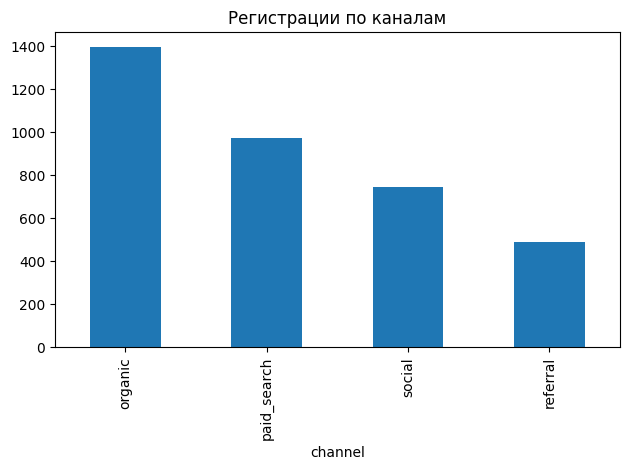

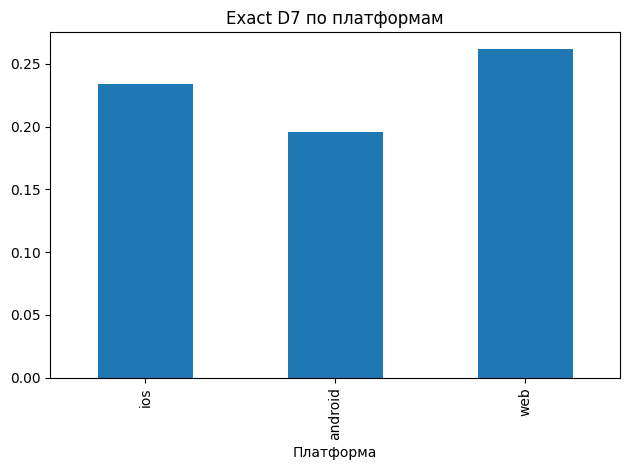

In [ ]:
acquisition['registrations'].plot(kind='bar', title='Регистрации по каналам')
plt.tight_layout(); plt.show()

result_table.set_index('Платформа')['Day-7 Retention Rate'].plot(kind='bar', title='Exact D7 по платформам')
plt.tight_layout(); plt.show()

In [ ]:
events['event_name'] = events['event_name'].astype(str)

last_day = events['event_time'].max().normalize()

cohort = users[['user_id','platform','registration_time']].copy()
cohort['registration_day'] = cohort.registration_time.dt.normalize()
cohort['d7_day'] = cohort.registration_day + pd.Timedelta(days=7)
cohort = cohort.loc[cohort.d7_day.le(last_day)].copy()

opens = events.loc[events['event_name'].eq('app_open'), ['user_id','event_time']].copy()
opens['open_day'] = opens.event_time.dt.normalize()
print("opens size:", len(opens))

ret = cohort.merge(opens[['user_id','open_day']], on='user_id', how='left')
ret['is_d7'] = ret.open_day.eq(ret.d7_day)

ret_user = (ret.groupby('user_id', as_index=False)['is_d7'].max()
             .rename(columns={'is_d7':'d7_ret'}))
cohort = cohort.merge(ret_user, on='user_id', how='left')
cohort['d7_ret'] = cohort['d7_ret'].fillna(False)

d7_total = cohort['d7_ret'].mean()
print('Общий exact D7:', round(d7_total, 4))
print('Вернувшихся на d7:', int(cohort['d7_ret'].sum()))

opens size: 23962
Общий exact D7: 0.2222
Вернувшихся на d7: 800


Вывод: Всего 3600 регистраций суммарно по всем каналам: organic, paid_search, referral, social. САС считаем только по платным каналам, для каждого можно посмотреть расход. Отдельно посчитали долю прошедших онбординг в течение 24 часов, а также создавших/завершивших задачи. Последние показатели оказались равны 0, что означает, видимо, создание задач в более поздний период использования приложения. В знаменателе у нас везде кол-во зарегистрированных пользователей. Retention считаем как exact day-7 retention. Но считаем только на тех пользователях, у которых есть полный 7-дневный период. Отдельно считаем retention по каждой платформе, общий по всем платформам как раз является средним значением. Revenue считаем как конверсию в платящего, тут тоже в знаменателе общее кол-во зарегистрированных, а в числителе - оплативших подписку. Также посчитали observed arpu - это все платежи/все зарегистрированные. Referral - считаем долю людей, которые отправили хотя бы одно приглашение. Пока что просто нужно дальше наблюдать за действиями внутри различных каналов.

## 05. HEART — 12 баллов

Для каждой из пяти категорий HEART предложи цель → signal → metric (Goals–Signals–Metrics). У FocusFlow **нет опросных данных**. Не выдумывай NPS и CSAT: опиши, какие дополнительные данные собрать для Happiness. Рассчитай доступные аналоги Engagement, Adoption, Retention, Task Success; оцени ограничения измерения успешности задачи по событиям.

**Критерии:** 7 б. GSM; 3 б. расчёты; 2 б. ограничения.

In [ ]:
# TODO: таблица HEART; расчёты для четырёх наблюдаемых компонент
heart = pd.DataFrame([
    ['Happiness', 'Пользователь доволен', 'ответ в опросе/жалобы в поддержку/ошибки', 'для CSAT нужен опрос, поэтому мы можем взять долю активных пользователей, у которых вылезали ошибки; можно оценить кол-во людей, возвращающихся в приложение на 7 день'],
    ['Engagement', 'Продукт приносит пользу, им регулярно пользуются', 'Есть много завершенных задач, приложение часто открывают, много люде регестрируется', 'completed per user для задач/среднее число сессий после app_open'],
    ['Adoption', 'Освоена базовая функция', 'создана первая задача', 'activation_24h'],
    ['Retention', 'Возвращение в продукт', 'возвращение на 7 день', 'exact-day D7'],
    ['Task Success', 'Задача выполнена без проблем', 'успех/попытки', 'нет ошибок или лишних попыток']
], columns=['HEART', 'Goal', 'Signal', 'Metric'])
display(heart)

,HEART,Goal,Signal,Metric
0,Happiness,Пользователь доволен,ответ в опросе/жалобы в поддержку/ошибки,"для CSAT нужен опрос, поэтому мы можем взять д..."
1,Engagement,"Продукт приносит пользу, им регулярно пользуются","Есть много завершенных задач, приложение часто...",completed per user для задач/среднее число сес...
2,Adoption,Освоена базовая функция,создана первая задача,activation_24h
3,Retention,Возвращение в продукт,возвращение на 7 день,exact-day D7
4,Task Success,Задача выполнена без проблем,успех/попытки,нет ошибок или лишних попыток


In [ ]:
completed = events.loc[events.event_name.eq('task_completed')]

engagement = len(completed) / completed.user_id.nunique()
task_created = completed = events.loc[events.event_name.eq('task_created'),'task_id'].nunique()
task_completed = created = completed = events.loc[events.event_name.eq('task_completed'),'task_id'].nunique()

print('Engagement: ', round(engagement,2))
print('\nAdoption:', round(a.created_24h.mean(),2))
print('\nREtention:', round(d7_total,2))
print('\nTask success: ', round(task_completed/task_created,2))

Engagement:  9.64

Adoption: 0.0

REtention: 0.22

Task success:  0.69


Вывод: Здесь мы отдельно расписали для каждгой категории цели, сигналы и метрики. Так как у нас нет опросных данных, то мы используем для метрики в happiness другой способ ее вычисления. В таблице подробно расписано, что означает и за что отвечает каждая категория. Мы также рассчитали отдельно доступные метрики для 4 оставшихся категорий. Для engagement - это среднее число завершенных задач на пользователя; adoption - доля создавших задачу в течение 24 часов; retention - exact day-7 retention; task success - доля завершенных задач. Успешность задач пока что сложно оценивать только по параметрам завершенности, так как их можно закрывать случайно или закрывать слишком быстр. Скорее всего, нам было бы также полезно учитывать диапазон времени между созданием и закрытием задачи. Или было бы хорошо добавить в приложение кнопку, где указывается задача выполнена полностью или частично, чтобы потом учитывать только полное выполнение.

## 06. North Star Metric — 12 баллов

Предложи 2 кандидата на NSM: (а) число завершённых задач за неделю, (б) число пользователей, завершивших ≥3 задачи за неделю. Выбери один, указав связь с ценностью и риск накрутки. Рассчитай обе метрики **по полным календарным неделям** на данных. Добавь две guardrail-метрики.

**Критерии:** 5 б. выбор; 5 б. расчёт; 2 б. guardrails.

In [ ]:
# TODO: таблица недель и динамика двух NSM-кандидатов

events['week'] = events.event_time.dt.to_period('W').dt.start_time

completed = events.loc[events.event_name.eq('task_completed')]

total_tasks = completed.groupby('week').task_id.nunique().rename('completed_tasks')

user_per_week = (completed.groupby(['week','user_id']).task_id.nunique().reset_index(name = 'tasks'))

three_tasks = (user_per_week.loc[user_per_week.tasks >=3].groupby('week').user_id.nunique().rename('users_with_3_tasks'))


NSM = pd.concat([total_tasks, three_tasks], axis = 1).fillna(0).astype(int)
display(NSM)

,completed_tasks,users_with_3_tasks
week,,
2026-08-31,1043,172
2026-09-07,3145,526
2026-09-14,4675,807
2026-09-21,5029,877
2026-09-28,4300,729
2026-10-05,2741,427
2026-10-12,889,98


In [ ]:
created_tasks_guard = events.loc[events.event_name.eq('task_created')].groupby('week').task_id.nunique().rename('created_tasks')
completed_tasks_guard = events.loc[events.event_name.eq('task_completed')].groupby('week').task_id.nunique().rename('completed_tasks')

guard_1 = (completed_tasks_guard/created_tasks_guard).rename('completion_rate')


active_guard = events.groupby('week').user_id.nunique().rename('active_users')
error_guard = events.loc[events.event_name.eq('error')].groupby('week').user_id.nunique().rename('users_with_error')
guard_2 = (error_guard/active_guard).rename('error_rate')

guardrails = pd.concat([guard_1, guard_2], axis =1 ).round(2)
display(guardrails)

,completion_rate,error_rate
week,,
2026-08-31,0.69,NaN
2026-09-07,0.70,0.06
2026-09-14,0.69,0.04
2026-09-21,0.69,NaN
2026-09-28,0.68,NaN
2026-10-05,0.70,NaN
2026-10-12,0.69,NaN


Вывод: У нас есть 2 кандидата на NSM: (а) число завершённых задач за неделю, (б) число пользователей, завершивших ≥3 задачи за неделю. Я думаю, что лучше брать метрику (a), потому что так мы можем знать, сколько каждый пользователь завершает задач за неделю и считать средний показатель по всем юзерам. Мы будем оценивать кол-во задач по всем пользователям, а не брать только тех, у которых >=3. Их может быть гораздо меньшее кол-во, лучше брать как всопомгательную метрику. Так мы действительно сможем понять, сколько именно людей доводят задачи до конца, определяют для себя ценность продукта. Конечно, здесь есть риск того, что многие люди, особенно в начале пользования, могут создавать и завершать задачи, чтобы опробовать функционал. Тогда у нас будет немного смещенная оценка. В качестве guardrail метрик берем completion_rate и error_rate. Это нужно для того, чтобы верно отслеживать число завершенных задач за неделю.

## 07. Metric Tree — 16 баллов

Построй **точную арифметическую декомпозицию**:

`Completed tasks = Registered users × Active share × Created tasks per active × Completion rate per created task`

Здесь `Active share` — доля зарегистрированных, создавших ≥1 задачу за период; `Created tasks per active` — созданные задачи / создавшие ≥1 задачу; `Completion rate` — число **уникальных task_id** с task_completed / уникальных task_id с task_created. Проверь алгебраически и программно, что дерево восстанавливает итоговую метрику (с учётом того, что у каждого task_id одна пара create/complete).

Предложи, какая ветка потенциально управляемая командой. Отличи **тождество** от гипотезы о причинности.

**Критерии:** 10 б. корректное равенство; 3 б. визуализация; 3 б. управленческое применение.

In [ ]:
# TODO: дерево в Markdown/диаграмме + код проверки через np.isclose
active_users = events.loc[events.event_name.eq('task_created'),'user_id'].nunique()
active_share = active_users / n_users

created_tasks = events.loc[events.event_name.eq('task_created'),'task_id'].nunique()
created_tasks_per_active = created_tasks / active_users

completed_tasks = events.loc[events.event_name.eq('task_completed'),'task_id'].nunique()
completion_rate_per_created_task = completed_tasks / created_tasks

print('Registered users: ', n_users)
print('\nActive users: ', active_users)
print('\nActive share: ', round(active_share,2))
print('\nCreated tasks: ', created_tasks)
print('\nCreated tasks per active user: ', round(created_tasks_per_active))
print('\nCompleted tasks: ', completed_tasks)
print('\nCompletion rate per created task: ', round(completion_rate_per_created_task))

Registered users:  3600

Active users:  2270

Active share:  0.63

Created tasks:  31541

Created tasks per active user:  14

Completed tasks:  21822

Completion rate per created task:  1


In [ ]:
tasks_decomposure = n_users*active_share*created_tasks_per_active*completion_rate_per_created_task
print('Tasks decomposure: ', round(tasks_decomposure,2))
print('Верно ли тождество?', 'Да' if np.isclose(completed_tasks, tasks_decomposure, rtol=1e-9) else 'Нет')

Tasks decomposure:  21822.0
Верно ли тождество? Да


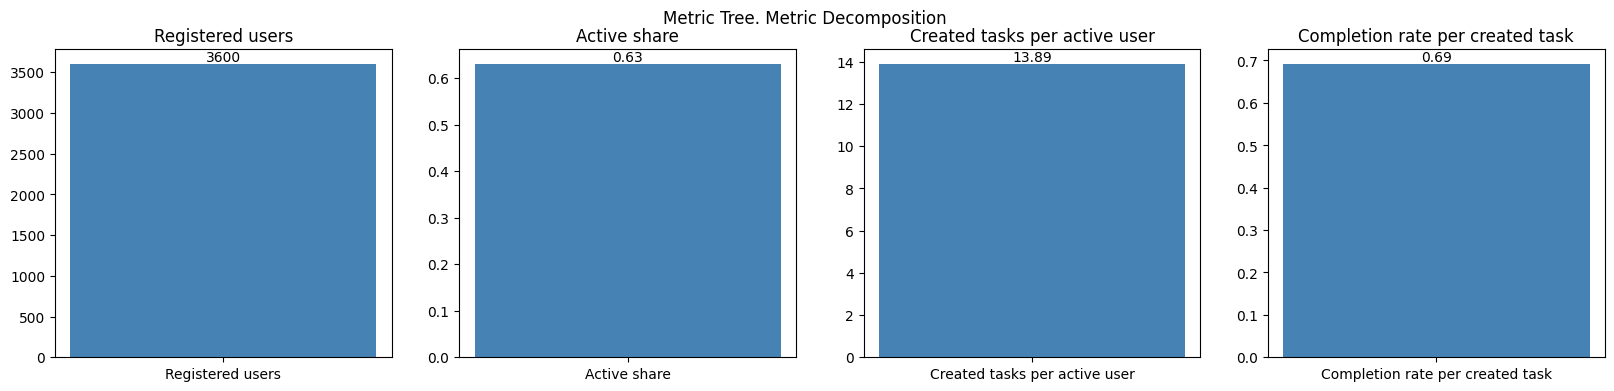

In [ ]:
labels = ['Registered users','Active share','Created tasks per active user','Completion rate per created task']
values = [n_users,active_share,created_tasks_per_active,completion_rate_per_created_task]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, lab, val in zip(axes, labels, values):
    ax.bar([lab], [val], color='steelblue')
    ax.set_title(lab)
    ax.text(0, val, f'{val:.2f}' if val < 100 else f'{val:.0f}', ha='center', va='bottom')
plt.suptitle('Metric Tree. Metric Decomposition')
plt.show()


Вывод: Здесь мы отдельно рассчитали каждый показатель, из которого складываются выполненные задачи. Подтвердили тождество. Команда может управлять completion rate: больше напоминаний, больше пушей, быстрее фиксить ошибки пользователей. Благодаря тому, что можно так разделить на составляющие наше дерево, мы можем увидеть потенциальную ошибку. Если где-то у нас данных недостаточно или где-то вычислительная ошибка, то здесь это можно сразу увидеть. Однако, мы не можем с полной уверенностью утверждать, что, напмример, именно увеличение completion_rate поведет за собой рост completed_tasks. Может у нас также увеличилось бы active_share  и тд.

## 08. Когортный анализ и окна — 12 баллов

Построй матрицу D1/D7/D14 retention по дате регистрации (daily cohorts) либо по группам из 3 дней. Учитывай только полностью наблюдаемые когорты для каждого горизонта. Выдели закономерности и объясни, почему нельзя сравнивать самые свежие когорты с самыми старыми, если не контролировать срок наблюдения.

**Критерии:** 8 б. матрица; 4 б. объяснение.

In [ ]:
# TODO: матрица когорта × [D1, D7, D14] и heatmap/таблица

cohort =users[['user_id','registration_time']].copy()
cohort['registration_date'] = cohort.registration_time.dt.normalize()

cohort_size = cohort.groupby('registration_date').user_id.nunique().rename('size')

app_open_users = events_merged.loc[events_merged.event_name.eq('app_open'),['user_id','registration_date','day_n']].copy()


In [ ]:
events_merged.head()

,event_id,user_id,event_time,event_name,task_id,platform_x,registration_time,platform_y,channel,onboarding_in_hours,registration_date,event_date,day_n
0,40641,1735,2026-09-01 08:09:00,registration,NaN,web,2026-09-01 08:09:00,web,referral,0.000000,2026-09-01,2026-09-01,0
1,75521,3227,2026-09-01 08:09:00,registration,NaN,ios,2026-09-01 08:09:00,ios,paid_search,0.000000,2026-09-01,2026-09-01,0
2,40642,1735,2026-09-01 08:10:00,app_open,NaN,web,2026-09-01 08:09:00,web,referral,0.016667,2026-09-01,2026-09-01,0
3,75522,3227,2026-09-01 08:10:00,app_open,NaN,ios,2026-09-01 08:09:00,ios,paid_search,0.016667,2026-09-01,2026-09-01,0
4,58081,2479,2026-09-01 08:15:00,registration,NaN,android,2026-09-01 08:15:00,android,organic,0.000000,2026-09-01,2026-09-01,0


In [ ]:
def day_n_retention(n):
  cohort_date = cohort_size[cohort_size.index + pd.Timedelta(days = n) <= last_date]
  active_users_cohort = (app_open_users.loc[app_open_users.day_n.eq(n)].groupby('registration_date').user_id.nunique().reindex(cohort_date.index).fillna(0))

  return(active_users_cohort/cohort_date).rename(f'Day-{n}')


d1_retention = day_n_retention(1)
d7_retention = day_n_retention(7)
d14_retention = day_n_retention(14)

result = pd.concat([cohort_size,d1_retention,d7_retention, d14_retention], axis = 1).round(2)
display(result)

,size,Day-1,Day-7,Day-14
registration_date,,,,
2026-09-01,172,0.23,0.18,0.12
2026-09-02,187,0.26,0.21,0.16
2026-09-03,182,0.18,0.20,0.20
2026-09-04,182,0.23,0.23,0.13
2026-09-05,170,0.17,0.22,0.15
2026-09-06,196,0.23,0.25,0.16
2026-09-07,162,0.23,0.17,0.20
2026-09-08,166,0.27,0.23,0.17
2026-09-09,171,0.22,0.25,0.15


Вывод: По когортам мы построили матрицу day-1/day-7/day-14 retention по дате регистрации, учитывали только те данные, которые подходили под условие, что нам нужны полностью наблюдаемые когорты, полные. Иначе у нас были бы неверные расчеты, так как мы брали обрезанные значения. Если посмотреть на day-1 retention по дням, то все значения, в основном, не сильно отклоняются друг от друга. С day-7 retention есть колебания в период с 16 по 17 сентября по сравнению с 15 числом. Мы не можем утверждать, что это связано с кол-вом ошибок в этот день или, может, качеством трафика. Нужно провести отдельные наблюдения в эти дни, чтобы разобраться, почему метрика так сильно упала. Day-14 retention уже гораздо ниже по показателям, чем day-1 retention, но это предсказуемо, так как человек легче вернуться в приложение на следующий день, чем на 14. Очевидно, что людей, которые стабильно пользуются приложением в течение двух недель, будет меньше. Мы можем сравнивать одинаковые по возрасту когорты, потому что есть множество несопоставимых факторов у когорт разного возраста, например, сезонность аудитории, канал привлечения. Мы также не можем сравнивать day-1 с day-14, так как у первой когорты просто недостаточно данных для сравнения, она неполная. Соответсвенно, сравнение будет некорректным.

## 09. Диагностика Android — 12 баллов

Исследуй сообщения об ошибках и task completion по платформам **до (1–9 сентября), во время (10–16 сентября), после (17–30 сентября)**. Правильно выбирай denominator — например, completion per created task и доля активных пользователей с ошибкой. Объясни как минимум три альтернативных объяснения изменений; опиши эксперимент или дополнительный сбор данных для проверки гипотезы о влиянии ошибок.

**Критерии:** 7 б. сегментный расчёт; 5 б. обоснование.

In [ ]:
# TODO: платформы × период × error_rate / task_completion_rate

def period(t):
  if t<pd.Timestamp('2026-09-10'): return '1-9 сентября'
  if t<=pd.Timestamp('2026-09-16 23:59:59'): return '10-16 сентября'
  return '17-30 сентября'

In [ ]:
ev = events.merge(users[['user_id','platform']], on='user_id', how='left', suffixes=('','_user'))
ev['period'] = ev.event_time.apply(period)

In [ ]:
ev

,event_id,user_id,event_time,event_name,task_id,platform,week,platform_user,period
0,40641,1735,2026-09-01 08:09:00,registration,NaN,web,2026-08-31,web,1-9 сентября
1,75521,3227,2026-09-01 08:09:00,registration,NaN,ios,2026-08-31,ios,1-9 сентября
2,40642,1735,2026-09-01 08:10:00,app_open,NaN,web,2026-08-31,web,1-9 сентября
3,75522,3227,2026-09-01 08:10:00,app_open,NaN,ios,2026-08-31,ios,1-9 сентября
4,58081,2479,2026-09-01 08:15:00,registration,NaN,android,2026-08-31,android,1-9 сентября
...,...,...,...,...,...,...,...,...,...
84638,13866,592,2026-10-15 23:15:00,task_completed,592-27-1,ios,2026-10-12,ios,17-30 сентября
84639,73710,3142,2026-10-15 23:30:00,subscription_renewed,NaN,web,2026-10-12,web,17-30 сентября
84640,84369,3589,2026-10-15 23:42:00,task_completed,3589-29-0,android,2026-10-12,android,17-30 сентября
84641,35038,1485,2026-10-15 23:44:00,task_completed,1485-25-0,web,2026-10-12,web,17-30 сентября


In [ ]:
created_tasks_platform = ev.loc[ev.event_name.eq('task_created')].groupby(['platform_user','period']).task_id.nunique().rename('created_tasks')
completed_tasks_platform = ev.loc[ev.event_name.eq('task_completed')].groupby(['platform_user','period']).task_id.nunique().rename('completed_tasks')

In [ ]:
platform_tasks = pd.concat([created_tasks_platform,completed_tasks_platform], axis=1).fillna(0)
platform_tasks

created_tasks  completed_tasks
platform_user period                                        
android       1-9 сентября             1309              905
              10-16 сентября           1994             1369
              17-30 сентября           9132             6332
ios           1-9 сентября             1286              896
              10-16 сентября           2263             1579
              17-30 сентября           9054             6215
web           1-9 сентября              603              429
              10-16 сентября           1082              759
              17-30 сентября           4818             3338

In [ ]:
platform_tasks['completion_rate'] = (platform_tasks.completed_tasks/platform_tasks.created_tasks).round(2)
display(platform_tasks)

created_tasks  completed_tasks  completion_rate
platform_user period                                                         
android       1-9 сентября             1309              905             0.69
              10-16 сентября           1994             1369             0.69
              17-30 сентября           9132             6332             0.69
ios           1-9 сентября             1286              896             0.70
              10-16 сентября           2263             1579             0.70
              17-30 сентября           9054             6215             0.69
web           1-9 сентября              603              429             0.71
              10-16 сентября           1082              759             0.70
              17-30 сентября           4818             3338             0.69

In [ ]:
active = ev.groupby(['platform_user','period']).user_id.nunique().rename('active')
with_err = ev.loc[ev.event_name.eq('error')].groupby(['platform_user','period']).user_id.nunique().rename('with_error')
err = pd.concat([active, with_err], axis=1).fillna(0)
err['error_share'] = (err.with_error / err.active).round(2)
display(err)

active  with_error  error_share
platform_user period                                         
android       1-9 сентября       702         0.0          0.0
              10-16 сентября     922       187.0          0.2
              17-30 сентября    1037         0.0          0.0
ios           1-9 сентября       580         0.0          0.0
              10-16 сентября     836         0.0          0.0
              17-30 сентября     985         0.0          0.0
web           1-9 сентября       306         0.0          0.0
              10-16 сентября     419         0.0          0.0
              17-30 сентября     512         0.0          0.0

Вывод: Здесь мы сравниваем кол-во выполненных задач и кол-во ошибок в разные периоды. В таблице с completion_rate мы видим, что на Android показатели стабильно хорошие по всем периодам, на IOS и на WEB тоже в целом такие же. Однако, если посмотреть на таблицу с кол-во ошибок по каждой платформе, то, как до этого и говорилось ранее, страдает от этой проблемы только Android. Хоть кол-во ошибок и не повлияло никак на completion_rate, но откуда все же они взялись?
Ошибки могут быть связаны с обновлением приложения, но могут возникать не при создании задач, поэтому completion_rate не меняется. Может быть, у нас сменилась аудитория, которая работает с приложением, им тяжелее с ним работать, отсюда и возникают ошибки. Может быть, ошибки связаны с перегруженностью, возникают, когда очень много пользователей пытаются работать с приложением. Все эти ошибки могут возникать на любой платформе, но на Android в этот раз их вышло больше всего. Чтобы понять причину ошибок, их природу, нам необходимо также собирать данные по тому, что именно это за ошибка, где возникла, смотреть причину. У нас в данных мы просто знаем, что была какая-то ошибка. Непонятно, связано это напрямую с созданием и завершением задач или нет. Судя по тому, что на кол-во завершенных задач это не повлияло, то ошибки возникали в других местах, например, если у нас все же есть вход через соц.сети, то при попытке воспользоваться этой функцией. Для подсчета completion_rate мы берем кол-во завершенных/кол-во созданных. Для подсчета error_rate мы берем кол-во людей с ошибкой/кол-во активных пользователей. Разные знаменатели, разные показатели. Для изучения связи метрик нужно больше данных по ошибкам: версии приложений, причина возникновения и тд.

## 10. Unit Economics без ложных LTV — 14 баллов

Стоимость подписки — 399 ₽/платёж. Маркетинговые расходы заданы в отдельном CSV. **Допущения (синтетические):** переменная стоимость обслуживания 65 ₽ на каждый успешный платёж и 25 ₽ на каждого зарегистрированного пользователя за весь период наблюдения.

Рассчитай CAC **зарегистрированного** и CAC **первого платящего** пользователя по платным каналам, observed revenue, observed contribution margin (после указанных переменных затрат), Payback за наблюдаемый период, если возможно, и объясни, почему полноценный LTV нельзя надёжно получить из доступного короткого окна. Не подставляй произвольный «средний срок жизни».

**Критерии:** 9 б. расчёты; 5 б. интерпретация и оговорки.

In [ ]:
# TODO: таблица экономики по каналам; все допущения подписаны
subscription_price = 399
succ_payment = 65
invite_payment = 25

payers = payments.groupby('user_id').agg(payments = ('payment_id','count'),revenue = ('amount_rub','sum'))
first_payers = payments.loc[payments.payment_type.eq('first'),'user_id'].unique()

In [ ]:
payers

,payments,revenue
user_id,,
10,2,798
33,2,798
39,1,399
41,1,399
57,1,399
...,...,...
3558,1,399
3560,1,399
3561,1,399


In [ ]:
first_payers

array([1960,   33, 1813, 1575, 2901,  119,   10,  747, 1016, 2789, 3248,
        406,  893, 3541, 2382, 2547,  720,  275, 1206, 1227, 2776, 1942,
       2126, 1487, 1568, 1250, 1232,  340,  521, 2265, 2927,  925, 1933,
        938, 3552, 2640,  386,  547, 2340, 2694, 1168,  520, 1264, 2863,
       1652, 2167, 2542, 3517, 1734, 3120, 1512, 3171, 3588,  725, 1129,
       2075, 1513, 2957, 2466, 1409,  590, 1150, 1785,  827, 1401, 1127,
        475,   74, 2379, 3190, 1468,  428,  514, 1026, 3037, 2613,  478,
       1216, 1867,   41,  618, 1268, 2786, 3460, 2642, 2697, 3470, 2229,
       2737, 2199, 3144, 3328,  553,  192, 2569, 1455,  513, 1045, 2392,
        398, 2660,  450, 1199, 2127, 2350, 3321, 1139,  611,  232, 1145,
       2922,  160, 2930, 3142,  924, 1902, 1066, 2525,   39, 2746, 2828,
       1025, 1217, 2429, 1350,  159, 3058, 1391, 2519,  957,  435, 2042,
        533, 2890, 3284, 1236,  709, 2315, 1528, 3242, 2407, 2311, 3092,
       2461,  117, 1930, 2275, 3382, 3344, 2248, 26

In [ ]:
rows = []
for channel in users.channel.unique():
  user_channel = users.loc[users.channel.eq(channel),'user_id']
  n_channel = user_channel.nunique()
  n_first = len(set(user_channel) &set(first_payers))
  channel_spend = marketing.set_index('channel').marketing_spend_rub.get(channel,0)

  channel_revenue = payers.reindex(user_channel).revenue.fillna(0).sum()
  channel_payments = payers.reindex(user_channel).payments.fillna(0).sum()
  var_payments = succ_payment*channel_payments+n_channel*invite_payment
  contribution = channel_revenue - var_payments

  rows.append({
        'channel': channel,
        'registrations': n_channel,
        'first_payers': n_first,
        'spend': channel_spend,
        'CAC_reg': round(channel_spend / n_channel, 0) if n_channel else np.nan,
        'CAC_first': round(channel_spend / n_first, 0) if n_first else np.nan,
        'observed_revenue': channel_revenue,
        'observed_contribution': contribution,
        'payback_observed': round(contribution / channel_spend, 3) if channel_spend else np.nan,
    })

unit_results = pd.DataFrame(rows)
display(unit_results)

,channel,registrations,first_payers,spend,CAC_reg,CAC_first,observed_revenue,observed_contribution,payback_observed
0,social,746,34,92000,123.0,2706.0,16758.0,-4622.0,-0.050
1,organic,1394,127,0,0.0,0.0,65835.0,20260.0,NaN
2,referral,489,45,28000,57.0,622.0,24738.0,8483.0,0.303
3,paid_search,971,71,180000,185.0,2535.0,37905.0,7455.0,0.041


Вывод: По каждому платному каналу рассчитали CAC, выручку, revenue, а также окупаемость. Канал organic принес нам много денег, при этом в его развитие мы не вкладывались. Канал social не окупился, у него отрицательный Payback, он убыточем по наблюдаемому периоду. У остальных платных каналов все ок. Полноценный LTV посчитать мы не можем, так как у нас слишком короткое наблюдаемое окно. Пока что слишком мало данных, чтобы адекватно оценивать прибыль, которую бы приносило приложение. Все остальные показатели, которые мы пока что могли рассчитать, были посчитаны.


## 11. Приоритизация и дизайн эксперимента — 10 баллов

Сформулируй 3 продуктовые гипотезы из полученных результатов. Для одной: сегмент, изменение, unit of randomization, primary/secondary/guardrail metrics, окно, критерий остановки, риски spillover и sample ratio mismatch. Выдели связь с деревом метрик и HEART.

**Критерии:** 4 б. гипотезы; 6 б. дизайн.

In [ ]:
# TODO: описание A/B-дизайна в Markdown

1. Вход через социальные сети. Я думаю, что если добавить на экран регистрации возможность быстрого входа через соц. сети, то больше людей будет пользоваться основными функциями приложения. Больше людей -> больше задач -> completion_rate станет выше -> кол-во платных подписок больше.
2. Напоминание о надобности завершения задач. Если следить за датой завершения задач, то можно отправлять пользователю напоминание о том, что срок задачи близится к концу. Часть пользователей таким образом будет завершать больше задач, заходить в приложение и их закрывать.
3. Фикс ошибок на Android. Также все же нужно починить ошибки на Android, посмотреть как это повлияет на comletion_rate, станет ли он еше выше. Повляет ли это на retention и тд. Но для начала нужно посмотреть, что это за ошибки и возникают ли они при создании/завершении задач.

Построим A/B тест для первой гипотезы.
Сегмент: новые пользователи, которые еще не прошли регистрацию.
Изменение: Берем тестовую группу, для нее на экране регистрации добавляет кнопки для входа через соц.сети.
Unit of randomization: случайно выбираем по user_id или по device_id.
Primary metric: conversion to registration. смотрим число уникальных юзеров с событием регистрации от кол-ва всех юзеров.
Secondary metric: exact day-7 retention; доля зарегистрировавшихся пользователей, которые завершили onboarding или создали первую задачу.
Guardrail metric: доля пользователей, которые после регистрации не создали ни одной задачи; conversion to payer; доля ошибок.
Окно: 14-30 дней. Нам нужно смотреть day-7 retention, поэтому точно берем больше, чем этот наблюдаемый период.
Критерий останровки: Если значительно упали guardrail метрики, например, conversion to payer. Успех достигается при увеличении конверсии зарегистрированных пользователей и при отсутствии ухудшения guardrail метрик.
Риски: пользователь может заходить с разных устройств и тогда по device_id может попадать в разные группы. Также может быть разделенеи аудитории по каналам привлечения, где-то может быть больше проплаченных пользователей. Везде должно быть одинаковое кол-во.

С деревом метрик и HEART здесь прямая связь, так как кол-во зарегистрированных пользователей как раз убдет влиять на Acqusition в первом случае и по Adoption во втором. вторичные метрики также повлияют на Adoption и Retention.



## 12. Executive memo — 8 баллов

Напиши записку Product Manager на **300–500 слов**: проблема → доказательства → ограничения → 2 альтернативы → одно рекомендуемое действие → измерение эффекта. Добавь ссылки на таблицы/графики в своём Notebook.

**Критерии:** 3 б. точность; 3 б. приоритизация; 2 б. коммуникация.

In [ ]:
# TODO: итоговая записка текстом, не кодом

Проблема: Количество регистраций растёт, но команда не уверена, что пользователи получают ценность. Часть Android-пользователей жалуется на ошибки.

Доказательства: В разлделе 4 видно, что onboarding в течение 24 часов проходит 78.6% пользователей, но при этом показатели создавших/завершивших первую задачу остаются нулевыми. Exact day-7 retention на Android ниже, чем на других платформах. В разделе 10 можно увидеть выручку и вклад в каджый из каналов, social дает убыток. Каналы почти не окупаются. Раздел 9 дает нам оценить completion_rate и error_rate по каждой из платформ, где оказыватеся, что хоть кол-во ошибок у пользователей android и возросло, но на completion_rate это не повлияло. Нужно изучить тогда, откуда именно пришли эти ошибки. В разделе 7 мы обратили внимание на то, что completion_rate - это та метрика, которой легче всего будет управлять.

Ограничения: У нас мало данных, которые мы можем наблюдать. По этой причине мы не можем полноценно посчитать LTV. Также у нас есть различия по каналам привлечения, но влияние этого на наши показатели мы однозначно не можем показать на данный момент.

2 альтернативы: работа с ошибками пользователей может напрямую влиять на completion_rate, но если только эти ошибки правда связаны с задачами. Также вход через соц.сети может значительно упростить знакомство с приложением и повлиять на увеличение completion_rate, а, соответственно, и увеличить кол-во людей, которым действительно помогает наш продукт.

Рекомендуемое действие: Наверное, все же для начала стоит пофиксить ошибки на Android. Это нужно сделать прежде, чем выкатывать вход через соц.сети, иначе кол-во ошибок может увеличиться, т.к. увеличиться и кол-во пользователей.

Измерение жффекта: Можно разделить пользователей опять на 2 группы: тестовую и контрольную. Только android. Нам нужно сначала определить primary, secondary и guardrail метрики. Пусть prinmary будет все тот же completion_rate, secondary - error_rate, а  guardrail - жалобы и новые ошибки, ухудшение completion_rate. Если кол-во завершенных задач возрасло и кол-во ошибок уменьшилом, значит уже можно по всем пользователям распространять тест. И можно раскатать соц. вход.